# MS/MS 碎片指认

为实测 MS/MS 峰寻找对应的分子碎片。

MAGMa 枚举分子图的碎片，并与实测峰的质量进行匹配。每条指认包含碎片分子式、质量误差及原子／键编号。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('ms.annotation.magma')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: ms.annotation.magma
Examples: 2


## 输入与输出

| Field | Meaning |
| --- | --- |
| `smiles / peaks` | 已知结构、实测 MS/MS 峰 [m/z, 相对强度] 及加合物。 |
| `ppm_tolerance` | 质量误差容限，默认 10 ppm；不是 NMR 化学位移容限。 |

| Field | Meaning |
| --- | --- |
| `peak_annotations` | 候选碎片、分子式、质量误差及 engine_smiles 上的原子/键编号。 |
| `interpretation` | 候选碎片结构及匹配质量误差。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C1=CC=C(C(=C1)C2=CC=C(C=C2)C(=O)O)C3=NNN=N3",
    "adduct": "[M+H]+",
    "observed_peaks": {
      "length": 40,
      "first_values": [
        [
          86.0158,
          0.14814814814814814
        ],
        [
          87.0237,
          0.16016016016016016
        ],
        [
          97.0082,
          0.06906906906906907
        ],
        [
          98.0159,
          1.0
        ],
        [
          99.0096,
          0.05305305305305305
        ],
        [
          99.0229,
          0.3783783783783784
        ],
        [
          100.0176,
          0.02002002002002002
        ],
        [
          100.0303,
          0.08208208208208208
        ]
      ]
    }
  },
  "sample_id": "MassSpecGymID0046618",
  "output": {
    "engine_smiles": "O=C(O)c1ccc(-c2ccccc2-c2nn[nH]n2)cc1",
    "peak_annotations": {
      "length": 40,
      "first_values": [
        {
          "peak_id": 7,
          "mz": 86.0158,
          "intensity": 0.1

## 评估预测

报告峰匹配覆盖率及 ppm 单位的质量误差。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | matched_peak_fraction | 0.568182 |
| recorded evaluation | recorded model | annotated_spectra | 2 |
| recorded evaluation | recorded model | checked_fragments | 1534 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 2
}


## 查看结果图

实测 MS/MS 峰对应的碎片结构。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

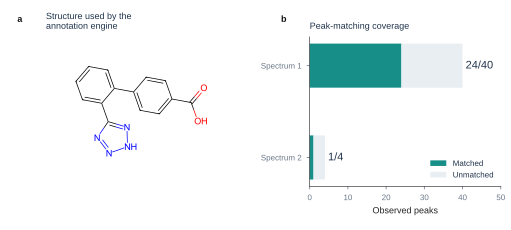

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('ms.annotation.magma', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks ms.annotation.magma --limit 8 --output results/ms-annotation-magma.json
```

[Task](../tasks/ms-annotation-magma.md) · [Quick start](../quickstart.md)



## 参考文献

- Ridder, L., van der Hooft, J. J. J. & Verhoeven, S. Automatic Compound Annotation from Mass Spectrometry Data Using MAGMa. Mass Spectrometry 3, S0033 (2014). doi:10.5702/massspectrometry.S0033. [Source](https://doi.org/10.5702/massspectrometry.S0033)
- Bushuiev, R., Bushuiev, A., de Jonge, N. F., Young, A., et al. MassSpecGym: A benchmark for the discovery and identification of molecules. Advances in Neural Information Processing Systems 37, Datasets and Benchmarks Track (2024). arXiv:2410.23326. [Source](https://arxiv.org/abs/2410.23326)
